<div style="background-color: #ccccff ; padding:10px; font-size:x-large; font-weight: bold">
EGD103 Tutorial 10 - Analysing Energy Demand Data
</div>

In this practice assignment, you will be analysing energy demand data collected by the Australian Energy Market Operator (AEMO) in 2023. 

There are two datasets - one containing demand data and one containing price data. These are available on Canvas. Demand and generation values are measured in MegaWatts (MW), and prices are measured in dollars per MegaWatt hour ($/MWh).


## Allowed Imports
You are allowed to use the imports given in the cell below when completing the assignment. Run the cell to import. Do not repeat yourself by adding import statements later in the assignment.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

***


<div style="background-color: #b2efb2; padding:10px; font-size:small; font-weight: bold">

## Part A: Inspecting and preparing data



### A1: Importing data
Import the two datasets as pandas dataframes. Make sure that columns with dates and/or times are imported in datetime format. Inspect the data to ensure it has been imported correctly.

Useful functions: <code>pd.read_csv</code>.

In [2]:
# demand import
date_cols = ['STARTDATE', 'ENDDATE']
demand = pd.read_csv('demand.csv', parse_dates=date_cols)
demand.info()

<class 'pandas.DataFrame'>
RangeIndex: 525750 entries, 0 to 525749
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype                    
---  ------          --------------   -----                    
 0   STARTDATE       525750 non-null  datetime64[us, UTC+10:00]
 1   ENDDATE         525750 non-null  datetime64[us, UTC+10:00]
 2   REGIONID        525750 non-null  str                      
 3   DEMAND          525750 non-null  float64                  
 4   GENERATION      525750 non-null  float64                  
 5   DEMANDFORECAST  525750 non-null  float64                  
dtypes: datetime64[us, UTC+10:00](2), float64(3), str(1)
memory usage: 24.1 MB


In [3]:
# prices import
prices = pd.read_csv('prices.csv', parse_dates=date_cols)
prices.info()

<class 'pandas.DataFrame'>
RangeIndex: 525600 entries, 0 to 525599
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype                    
---  ------     --------------   -----                    
 0   STARTDATE  525600 non-null  datetime64[us, UTC+10:00]
 1   ENDDATE    525600 non-null  datetime64[us, UTC+10:00]
 2   REGIONID   525600 non-null  str                      
 3   RRP        525600 non-null  float64                  
dtypes: datetime64[us, UTC+10:00](2), float64(1), str(1)
memory usage: 16.0 MB


### A2: Joining data
Combine the two datasets together by joining them based on the datetime and location. Inspect the result to make sure it joined correctly.

Useful methods: <code>merge</code>.

In [4]:
keys = ['STARTDATE', 'ENDDATE', 'REGIONID']
combined = demand.merge(prices, on=keys)
combined.info()

<class 'pandas.DataFrame'>
RangeIndex: 525750 entries, 0 to 525749
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype                    
---  ------          --------------   -----                    
 0   STARTDATE       525750 non-null  datetime64[us, UTC+10:00]
 1   ENDDATE         525750 non-null  datetime64[us, UTC+10:00]
 2   REGIONID        525750 non-null  str                      
 3   DEMAND          525750 non-null  float64                  
 4   GENERATION      525750 non-null  float64                  
 5   DEMANDFORECAST  525750 non-null  float64                  
 6   RRP             525750 non-null  float64                  
dtypes: datetime64[us, UTC+10:00](2), float64(4), str(1)
memory usage: 28.1 MB


### A3: Duplicate values
AEMO has informed you that there will occasionally be duplicate observations for a given datetime and location. In these instances the last observation is correct and the others should be removed. Check the data for these duplicates and correct if you find any.

Useful methods: <code>duplicated</code>, <code>sum</code>, <code>drop_duplicated</code>.

In [5]:
# inspecting duplicate values
combined.duplicated(subset=keys).sum()

np.int64(150)

In [6]:
# removing duplicate rows
combined = combined.drop_duplicates(subset=keys)

### A4: Organisation
Organise the dataframe to make sure it's sorted based on datetime. When multiple entries have the same datetime, it should sort based on the location.

Useful methods: <code>sort_values</code>.

In [7]:
combined = combined.sort_values(by=keys)
combined

,STARTDATE,ENDDATE,REGIONID,DEMAND,GENERATION,DEMANDFORECAST,RRP
0,2023-01-01 00:00:00+10:00,2023-01-01 00:05:00+10:00,NSW1,6906.63,6337.20,-0.90234,140.40
1,2023-01-01 00:00:00+10:00,2023-01-01 00:05:00+10:00,QLD1,5718.46,5830.28,7.95361,139.73
2,2023-01-01 00:00:00+10:00,2023-01-01 00:05:00+10:00,SA1,1443.65,1458.27,-4.16825,127.57
3,2023-01-01 00:00:00+10:00,2023-01-01 00:05:00+10:00,TAS1,1001.74,1209.37,-1.46765,450.10
4,2023-01-01 00:00:00+10:00,2023-01-01 00:05:00+10:00,VIC1,4676.57,4936.54,-39.37061,129.51
...,...,...,...,...,...,...,...
525745,2023-12-31 23:55:00+10:00,2024-01-01 00:00:00+10:00,NSW1,6587.63,6698.95,-19.00000,57.98
525746,2023-12-31 23:55:00+10:00,2024-01-01 00:00:00+10:00,QLD1,6294.38,5761.92,-50.00000,85.55
525747,2023-12-31 23:55:00+10:00,2024-01-01 00:00:00+10:00,SA1,1296.67,1131.61,-6.00000,54.02
525748,2023-12-31 23:55:00+10:00,2024-01-01 00:00:00+10:00,TAS1,1035.11,582.11,-2.00000,85.28


### A5: Further inspection
Conduct some further inspection to ensure the data is ready for analysis. You may want to consider the following:
* Are there any missing values?
* Are there any outliers?
* Domain / format checks

In [15]:
# inspecting missing values
combined.isna().sum()

STARTDATE         0
ENDDATE           0
REGIONID          0
DEMAND            0
GENERATION        0
DEMANDFORECAST    0
RRP               0
dtype: int64

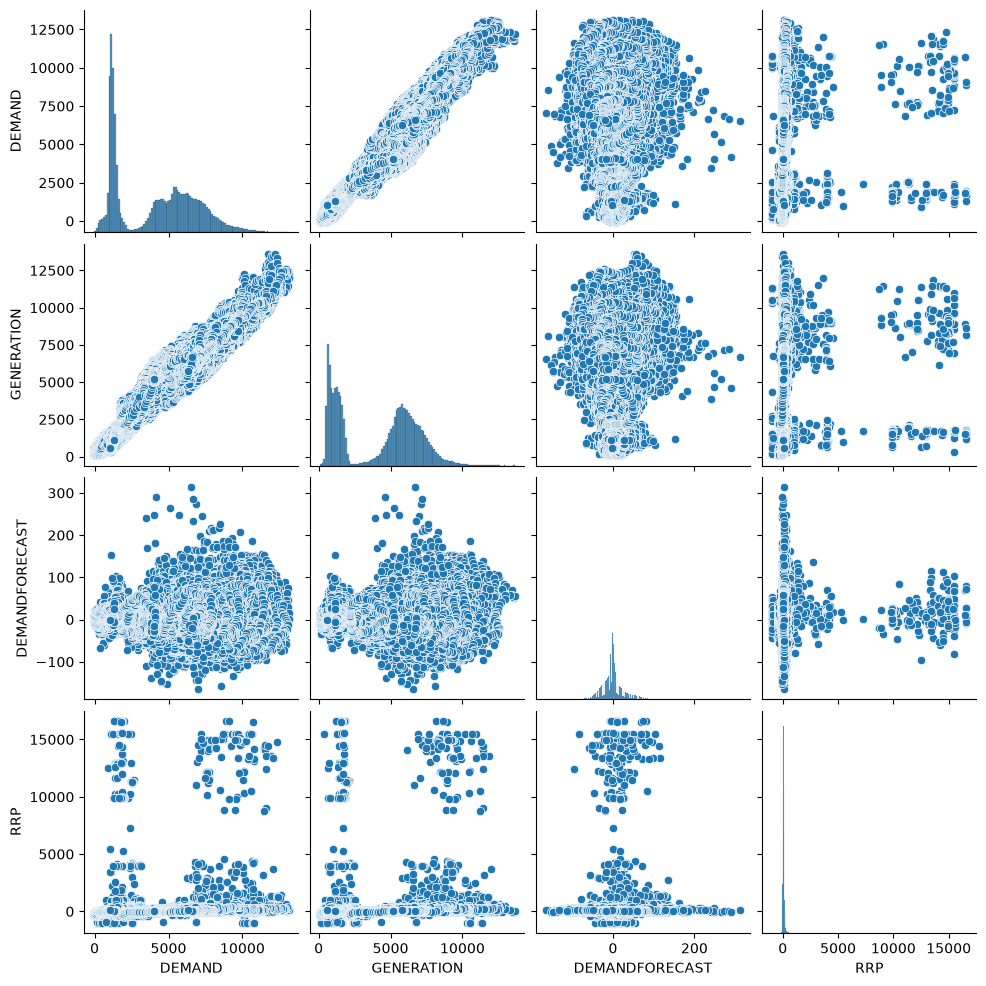

In [16]:
# checking for outliers - come interesting high-cost clusters, but this is due to policy
sns.pairplot(combined.loc[:, 'DEMAND': 'RRP'])

In [17]:
# location check
combined.REGIONID.value_counts()

REGIONID
NSW1    105120
QLD1    105120
SA1     105120
TAS1    105120
VIC1    105120
Name: count, dtype: int64

In [18]:
# checking 2023 only
combined.STARTDATE.min(), combined.ENDDATE.max()

(Timestamp('2023-01-01 00:00:00+1000', tz='UTC+10:00'),
 Timestamp('2024-01-01 00:00:00+1000', tz='UTC+10:00'))

In [19]:
# checking 5 minute intervals
time_diffs = combined.ENDDATE - combined.STARTDATE
time_diffs.unique()

<TimedeltaArray>
['0 days 00:05:00']
Length: 1, dtype: timedelta64[us]

### A6: Summary
Write a summary of your data preparation process in this Markdown cell.

The summary should discuss:
* Any possible errors you identified in the data.
* Any modifications you made to the data and why.
* A summary of what information is contained in the cleaned data.

The two datasets were joined so that the times and locations of the energy values and prices matched. There were found to be 150 duplicate rows which were removed. There were no obvious incorrect values in the data - location and time information is regular and there are no obvious outliers for the numeric variables. 

The resulting clean dataset contains the following varibles:
* STARTDATE
* ENDDATE
* REGIONID
* DEMAND
* GENERATION
* DEMANDFORECAST
* RRP

<div style="background-color: #b2efb2; padding:10px; font-size:small; font-weight: bold">

## Part B: Summarising data



### B1: What was the most expensive price in the data? When and where did it occur?

The maximum price in the data is 16600. This was recorded in South Australia on 01/08/2023 and 11/08/2023.

In [20]:
max_price = combined.RRP.max()
combined[combined.RRP == max_price]

,STARTDATE,ENDDATE,REGIONID,DEMAND,GENERATION,DEMANDFORECAST,RRP
306543,2023-08-01 18:30:00+10:00,2023-08-01 18:35:00+10:00,SA1,1974.02,1769.03,16.0,16600.0
320867,2023-08-11 17:15:00+10:00,2023-08-11 17:20:00+10:00,SA1,1610.90,1594.44,27.0,16600.0
320872,2023-08-11 17:20:00+10:00,2023-08-11 17:25:00+10:00,SA1,1601.68,1582.38,27.0,16600.0
321076,2023-08-11 20:45:00+10:00,2023-08-11 20:50:00+10:00,SA1,1804.14,1619.71,-8.0,16600.0
450553,2023-11-09 18:40:00+10:00,2023-11-09 18:45:00+10:00,SA1,1702.28,1518.59,11.0,16600.0
450557,2023-11-09 18:45:00+10:00,2023-11-09 18:50:00+10:00,SA1,1683.29,1540.03,9.0,16600.0
450564,2023-11-09 18:50:00+10:00,2023-11-09 18:55:00+10:00,SA1,1659.65,1527.06,4.0,16600.0
477507,2023-11-28 11:55:00+10:00,2023-11-28 12:00:00+10:00,SA1,1324.95,1212.88,-6.0,16600.0


### B2: How do prices compare between each location in the data? 
NSW is the most expensive region for electricty on average, with Tasmania and Victoria being the cheapest.

<Axes: xlabel='REGIONID', ylabel='Average RRP'>

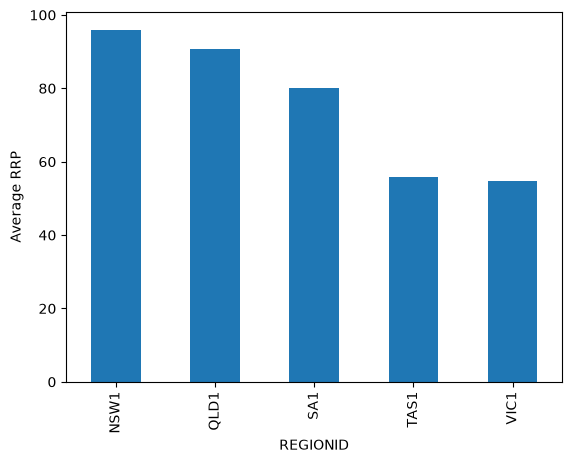

In [23]:
avg_price = combined.groupby('REGIONID').RRP.mean()
avg_price.plot(kind='bar', ylabel='Average RRP')

### B3: How does daily demand vary with time in the data? Are there any parts of the year that have noticably higher or lower demand than others?
There are two periodic trends with demand in the data. One has an annual period, with peaks in winter and summer where more heating and airconditioning systems are used. The high frequency noise suggests a weekly trend may be present as well.

<Axes: xlabel='DATE', ylabel='Average Daily Demand'>

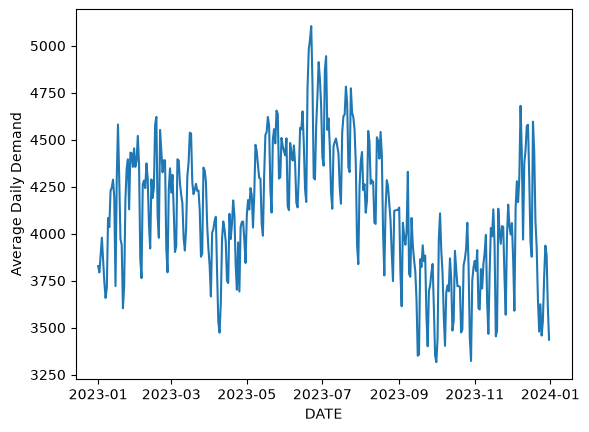

In [26]:
combined['DATE'] = combined.STARTDATE.dt.date
daily_demand = combined.groupby('DATE').DEMAND.mean()
daily_demand.plot(ylabel='Average Daily Demand')

### B4: Which two variables have the highest correlation in the data? How strong does their relationship look when plotted?
Generation and demand have the highest correlation in the data, with a coefficient of 0.97 indicating a very strong positive linear relationship. The scatter plot confirms the linear relationship between the variables.

In [28]:
# inspecting correlations
combined.corr(numeric_only=True)

,DEMAND,GENERATION,DEMANDFORECAST,RRP
DEMAND,1.000000,0.971114,0.002931,0.099474
GENERATION,0.971114,1.000000,0.003537,0.080237
DEMANDFORECAST,0.002931,0.003537,1.000000,0.036369
RRP,0.099474,0.080237,0.036369,1.000000


<Axes: xlabel='DEMAND', ylabel='GENERATION'>

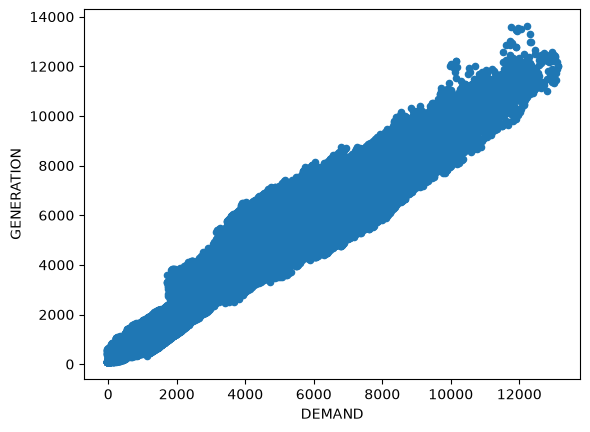

In [29]:
combined.plot(x='DEMAND', y='GENERATION', kind='scatter')

### B5: Your own research question
Write your worded response here.

In [13]:
# write code here

<div style="background-color: #b2efb2; padding:10px; font-size:small; font-weight: bold">

## Part C: Data integration

Demand forecasting is important for energy companies to ensure they can operate as profitably as possible. AEMO publishes there own demand forecasts to help companies with their decisions, but many companies will also have their own in-house forecasting tools to give them an advantage. In this part we will get you to develop your own forecasting tool and compare it to AEMO's forecasts.


### C1: A simple forecasting model
Create a user-defined function that accepts three inputs: a dataframe, a location id and a datetime. It should return the average of the last 5 changes in demand that occured for that location. If there aren't 5 previous changes, then it should a missing value eg. <code>None</code>, <code>NaN</code>. Your function should include exceptions that get raised if an invalid region or datetime is used when calling the function.

Hint: the pandas method <code>diff</code> is useful for computing the changes in demand.

In [32]:
def our_demand_forecast(df, region, datetime):
    # filter by region
    df =  df[df.REGIONID == region]
    
    # filter by datetime selected
    previous_halfhour = datetime - dt.timedelta(minutes=30)
    df = df[(df['STARTDATE'] > previous_halfhour) & (df['STARTDATE'] <= datetime)]
    if len(df) != 6:
        return None

    # compute differences
    changes = df['DEMAND'].diff()
        
    # mean difference
    avg_change = changes.mean()
    
    return avg_change

In [33]:
# add your own test cases here to make sure the function is working correctly.
our_demand_forecast(combined, 'QLD1', combined.STARTDATE[1000])

np.float64(49.66599999999998)

In [34]:
our_demand_forecast(combined, 'NSW1', combined.STARTDATE[2000])

np.float64(-14.257999999999992)

In [35]:
our_demand_forecast(combined, 'NSW1', combined.STARTDATE[4])

### C2: Creating a forecast column
Add a new column to the dataframe containing demand forecasts using the approach described in C1. This will allow you to compare your own forecasts to AEMO's.

Hint: the pandas method <code>diff</code> can again be useful here.

In [36]:
forecasts = combined.DEMAND.diff(periods=25) / 5
combined['MYDEMANDFORECAST'] = forecasts
combined

,STARTDATE,ENDDATE,REGIONID,DEMAND,GENERATION,DEMANDFORECAST,RRP,DATE,MYDEMANDFORECAST
0,2023-01-01 00:00:00+10:00,2023-01-01 00:05:00+10:00,NSW1,6906.63,6337.20,-0.90234,140.40,2023-01-01,NaN
1,2023-01-01 00:00:00+10:00,2023-01-01 00:05:00+10:00,QLD1,5718.46,5830.28,7.95361,139.73,2023-01-01,NaN
2,2023-01-01 00:00:00+10:00,2023-01-01 00:05:00+10:00,SA1,1443.65,1458.27,-4.16825,127.57,2023-01-01,NaN
3,2023-01-01 00:00:00+10:00,2023-01-01 00:05:00+10:00,TAS1,1001.74,1209.37,-1.46765,450.10,2023-01-01,NaN
4,2023-01-01 00:00:00+10:00,2023-01-01 00:05:00+10:00,VIC1,4676.57,4936.54,-39.37061,129.51,2023-01-01,NaN
...,...,...,...,...,...,...,...,...,...
525745,2023-12-31 23:55:00+10:00,2024-01-01 00:00:00+10:00,NSW1,6587.63,6698.95,-19.00000,57.98,2023-12-31,-11.638
525746,2023-12-31 23:55:00+10:00,2024-01-01 00:00:00+10:00,QLD1,6294.38,5761.92,-50.00000,85.55,2023-12-31,-29.422
525747,2023-12-31 23:55:00+10:00,2024-01-01 00:00:00+10:00,SA1,1296.67,1131.61,-6.00000,54.02,2023-12-31,-1.268
525748,2023-12-31 23:55:00+10:00,2024-01-01 00:00:00+10:00,TAS1,1035.11,582.11,-2.00000,85.28,2023-12-31,-4.374


### C3: Compute forecasting error columns
You should now have two forecast columns - one with AEMO's forecasts and one with your own. You now need to calculate the error for each forecast. This can be done by:
1. Finding the demand in the next 5-minute time period for that location.
2. Computing the actual change that occured in the demand.
3. Subtracting this from the forecast change to get the forecasting error.

Perform the process outlined above for each forecast column to compute forecast error columns.

Hint: the pandas method <code>shift</code> is very useful in this task. This can allow you to get the next demand in the same row as the current demand.

In [37]:
changes = combined.DEMAND.diff(periods=5)
changes = changes.shift(periods=-5)
combined['ACTUALCHANGE'] = changes
combined

,STARTDATE,ENDDATE,REGIONID,DEMAND,GENERATION,DEMANDFORECAST,RRP,DATE,MYDEMANDFORECAST,ACTUALCHANGE
0,2023-01-01 00:00:00+10:00,2023-01-01 00:05:00+10:00,NSW1,6906.63,6337.20,-0.90234,140.40,2023-01-01,NaN,-52.35
1,2023-01-01 00:00:00+10:00,2023-01-01 00:05:00+10:00,QLD1,5718.46,5830.28,7.95361,139.73,2023-01-01,NaN,3.01
2,2023-01-01 00:00:00+10:00,2023-01-01 00:05:00+10:00,SA1,1443.65,1458.27,-4.16825,127.57,2023-01-01,NaN,-5.49
3,2023-01-01 00:00:00+10:00,2023-01-01 00:05:00+10:00,TAS1,1001.74,1209.37,-1.46765,450.10,2023-01-01,NaN,-43.60
4,2023-01-01 00:00:00+10:00,2023-01-01 00:05:00+10:00,VIC1,4676.57,4936.54,-39.37061,129.51,2023-01-01,NaN,45.86
...,...,...,...,...,...,...,...,...,...,...
525745,2023-12-31 23:55:00+10:00,2024-01-01 00:00:00+10:00,NSW1,6587.63,6698.95,-19.00000,57.98,2023-12-31,-11.638,NaN
525746,2023-12-31 23:55:00+10:00,2024-01-01 00:00:00+10:00,QLD1,6294.38,5761.92,-50.00000,85.55,2023-12-31,-29.422,NaN
525747,2023-12-31 23:55:00+10:00,2024-01-01 00:00:00+10:00,SA1,1296.67,1131.61,-6.00000,54.02,2023-12-31,-1.268,NaN
525748,2023-12-31 23:55:00+10:00,2024-01-01 00:00:00+10:00,TAS1,1035.11,582.11,-2.00000,85.28,2023-12-31,-4.374,NaN


### C4: Analysing model errors
A common metric used to measure the accuracy of a model is Mean Absolute Error (MAE). This does the following:
* Find the absolute value of each error.
* Find the average (mean) of the absolute errors.

Do this for each of your error columns to compute the MAE for each forecasting model.

In [38]:
AEMO_error = combined.ACTUALCHANGE - combined.DEMANDFORECAST
our_error = combined.ACTUALCHANGE - combined.MYDEMANDFORECAST
# AEMO error
np.mean(np.abs(AEMO_error))

np.float64(30.58643471123203)

In [39]:
# our model's error
np.mean(np.abs(our_error))

np.float64(32.39124070247541)

### C5: Model summary
Write a summary of your forecasting model in this Markdown cell. The summary should discuss the following:
* How to use the model to forecast how much demand will change in the next 5 minutes.
* The average error to expect when using the model.
* How accurate your model is compared to AEMO's.
* Any possible improvements that could be made to the model.

Write summary in here.....